# California BEAD Broadband Subsidy Targeting
## Spatial Analysis of Broadband Equity Across Census Tracts

**Policy question**: California's BEAD (Broadband Equity, Access, and Deployment) programme has \$1.86B to allocate for broadband infrastructure. Which census tracts should receive infrastructure grants first, and does the answer differ by whether the broadband gap is driven by *market failure* (spatial spillovers: providers won't extend service because neighbours are also underserved) or *affordability* (low income: households can't subscribe even where service exists)?

**Three metrics this analysis tracks:**
- **Primary**: Broadband adoption rate per tract (↑ target: identify tracts ≤ 65% for subsidy)
- **Secondary**: Economic Disadvantage Index (EDI): composite of income, education, and broadband deficits (↑ means more deprived)
- **Guardrail**: Population coverage efficiency: what share of all underserved households does LL-cluster targeting actually reach?

**Analytical tension**: Spatial cold spots (LL clusters) signal infrastructure market failure and justify federal intervention, but they concentrate in rural, low-density areas. Dense urban tracts where broadband is low due to affordability constraints do NOT cluster spatially, so spatial targeting alone systematically under-prioritises them, even though they contain a large share of underserved households.

---

**Sections**
1. Setup & data
2. Exploratory analysis, distributions and correlations
3. Choropleth maps, income, broadband, county type
4. Global Moran's I, is broadband clustered?
5. LISA clusters, which tracts form cold spots?
6. Secondary outcome, Economic Disadvantage Index
7. Disaggregated analysis, subgroup Moran's I and OLS by county type
8. Spatial regression, OLS vs Lag vs Error
9. Guardrail analysis, population coverage efficiency
10. Decision synthesis and export

## 1. Setup & Data

We use a 400-tract synthetic dataset structured to match California ACS 2022 patterns. The synthetic generator plants a **shared latent 'urban proximity' factor** that drives income, education, AND broadband through the same channel, ensuring OLS controls are genuinely informative, not decorative. Spatial autocorrelation is planted via iterative box-blur on the broadband latent field.

The guardrail tension is also planted in the generator: 15 dense, low-income urban tracts receive suppressed broadband rates to simulate affordability barriers, a component that spatial clustering metrics will not detect.

In [1]:
import sys, yaml, json
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

from src.geo_urban.fetch import make_synthetic_geodataframe
from src.geo_urban.spatial_stats import build_weights, global_morans_i, lisa_clusters, subgroup_morans_i
from src.geo_urban.regression import run_ols, run_spatial_lag, run_spatial_error, compare_models, run_subgroup_ols, population_coverage_analysis
from src.geo_urban.maps import choropleth_map, lisa_map, county_type_map
from src.geo_urban.visualise import (
    plot_lisa_static, plot_moran_scatter, plot_regression_comparison,
    plot_broadband_distribution, plot_subgroup_regression,
    plot_guardrail, plot_edi_by_cluster,
)

OUTPUTS = ROOT / 'outputs'
OUTPUTS.mkdir(exist_ok=True)

cfg = yaml.safe_load((ROOT / 'config' / 'default.yaml').read_text())
geo_cfg = cfg['geography']
reg_cfg = cfg['regression']
scenario_cfg = cfg['scenario']

sns.set_theme(style='whitegrid', font_scale=1.05)
print('Config loaded.')
print(f"Scenario: {scenario_cfg['name']}")
print(f"Broadband threshold for 'underserved': {scenario_cfg['broadband_threshold']:.0%}")

Config loaded.
Scenario: California BEAD Broadband Subsidy Targeting
Broadband threshold for 'underserved': 65%


In [2]:
USE_SYNTHETIC = True   # Set False + provide CENSUS_API_KEY for real ACS data
CENSUS_API_KEY = None

if USE_SYNTHETIC:
    gdf = make_synthetic_geodataframe(
        n_tracts=scenario_cfg['n_tracts_synthetic'],
        seed=scenario_cfg['synthetic_seed'],
    )
    print(f'Loaded {len(gdf):,} synthetic tracts.')
else:
    from src.geo_urban.fetch import fetch_acs_data, fetch_tiger_shapefile
    from src.geo_urban.wrangle import merge_acs_tiger
    acs_df = fetch_acs_data(geo_cfg['state_fips'], cfg['acs_variables'],
                            year=geo_cfg['census_year'], census_api_key=CENSUS_API_KEY)
    tiger_gdf = fetch_tiger_shapefile(geo_cfg['state_fips'], year=geo_cfg['census_year'])
    gdf = merge_acs_tiger(acs_df, tiger_gdf,
                          projection_epsg=geo_cfg['projection_epsg'],
                          min_population=reg_cfg['min_population'])
    print(f'Loaded {len(gdf):,} real ACS tracts.')

print(f"\nCounty type breakdown:")
print(gdf['county_type'].value_counts().to_string())
print(f"\nBroadband rate summary:")
print(gdf['broadband_rate'].describe().round(3).to_string())

Loaded 400 synthetic tracts.

County type breakdown:
county_type
rural       161
urban       132
suburban    107

Broadband rate summary:
count    400.000
mean       0.539
std        0.231
min        0.180
25%        0.320
50%        0.545
75%        0.734
max        0.960


## 2. Exploratory Analysis, Distributions and Correlations

Before any spatial statistics, we want to understand the *unconditional* distribution of broadband access and how it relates to income. Two key questions:

1. Is the distribution of broadband rates unimodal, or does it have distinct groups suggesting structural separation between well-served and underserved areas?
2. How strongly does income predict broadband before controlling for spatial structure?

The correlation r gives the bivariate signal; residual spatial autocorrelation after controlling for income is what the regression models will later quantify.

Underserved tracts (broadband < 65%): 258 (64.5%)
Underserved households: 521,152

Pearson r (income × broadband): 0.713
Pearson r (education × broadband): 0.571


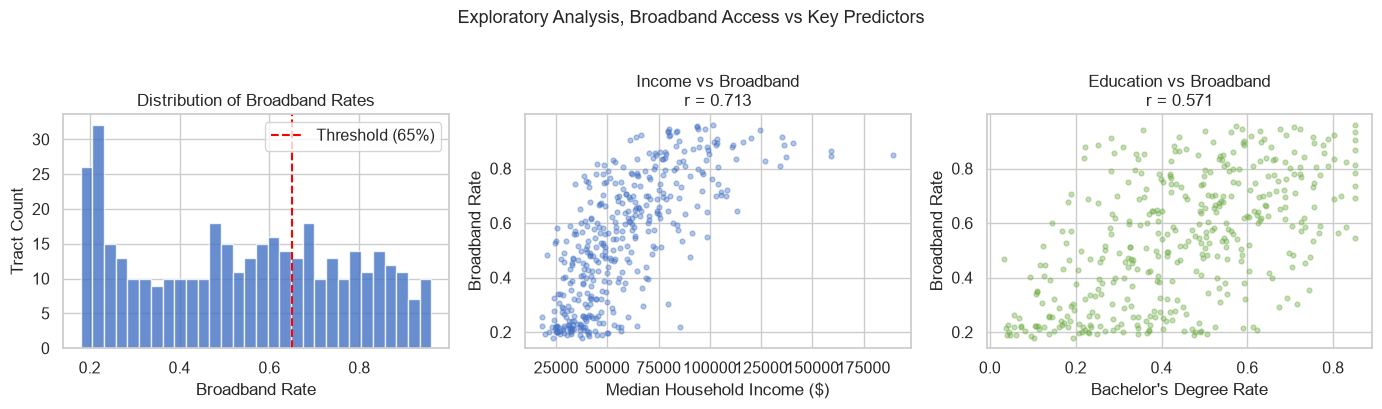

Saved exploratory_correlation.png


In [3]:
THRESHOLD = scenario_cfg['broadband_threshold']
underserved_count = (gdf['broadband_rate'] < THRESHOLD).sum()
underserved_pct = underserved_count / len(gdf) * 100

print(f"Underserved tracts (broadband < {THRESHOLD:.0%}): {underserved_count} ({underserved_pct:.1f}%)")
print(f"Underserved households: {gdf.loc[gdf['broadband_rate'] < THRESHOLD, 'population'].sum():,}")
print()

# Income-broadband correlation
r_inc_bb = gdf[['median_household_income','broadband_rate']].corr().iloc[0,1]
r_edu_bb = gdf[['bach_rate','broadband_rate']].corr().iloc[0,1]
print(f"Pearson r (income × broadband): {r_inc_bb:.3f}")
print(f"Pearson r (education × broadband): {r_edu_bb:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(gdf['broadband_rate'], bins=30, color='#4472C4', edgecolor='white', alpha=0.8)
axes[0].axvline(THRESHOLD, color='red', linewidth=1.5, linestyle='--', label=f'Threshold ({THRESHOLD:.0%})')
axes[0].set_xlabel('Broadband Rate')
axes[0].set_ylabel('Tract Count')
axes[0].set_title('Distribution of Broadband Rates')
axes[0].legend()

axes[1].scatter(gdf['median_household_income'], gdf['broadband_rate'],
                alpha=0.4, s=12, color='#4472C4')
axes[1].set_xlabel('Median Household Income ($)')
axes[1].set_ylabel('Broadband Rate')
axes[1].set_title(f'Income vs Broadband\nr = {r_inc_bb:.3f}')

axes[2].scatter(gdf['bach_rate'], gdf['broadband_rate'],
                alpha=0.4, s=12, color='#70AD47')
axes[2].set_xlabel('Bachelor\'s Degree Rate')
axes[2].set_ylabel('Broadband Rate')
axes[2].set_title(f'Education vs Broadband\nr = {r_edu_bb:.3f}')

plt.suptitle('Exploratory Analysis, Broadband Access vs Key Predictors', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(OUTPUTS / 'exploratory_correlation.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved exploratory_correlation.png')

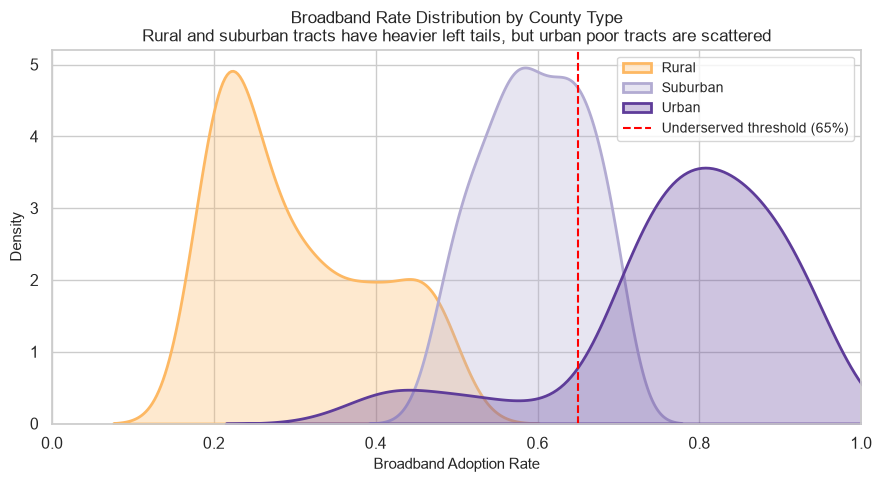

Saved broadband_distribution.png

Median broadband rate by county type:
             median   mean    min    max
county_type                             
rural         0.274  0.301  0.180  0.497
suburban      0.598  0.596  0.466  0.704
urban         0.801  0.781  0.363  0.960


In [4]:
# Broadband distribution by county type, reveals the structural heterogeneity
fig = plot_broadband_distribution(gdf, broadband_threshold=THRESHOLD,
                                  save_path=OUTPUTS / 'broadband_distribution.png')
plt.show()
print('Saved broadband_distribution.png')

print('\nMedian broadband rate by county type:')
print(gdf.groupby('county_type')['broadband_rate'].agg(['median','mean','min','max']).round(3).to_string())

## 3. Choropleth Maps, Income, Broadband, County Type

Interactive Folium choropleths provide spatial intuition before running any statistics. Three maps:
- Income: establishes the spatial pattern of economic resources
- Broadband: reveals where access is concentrated
- County type: the disaggregation lens, shows which zones are urban, suburban, rural

The key visual question: do income and broadband co-locate? If yes, the spatial regression will show income explains much of the broadband variance. If high-income areas have low broadband (visible outliers), that signals suppressed urban tracts, the affordability guardrail.

In [5]:
print('Building income choropleth ...')
_ = choropleth_map(
    gdf, column='median_household_income',
    title='Median Household Income by Census Tract',
    caption='Median Household Income ($)',
    colormap='YlOrRd',
    save_path=OUTPUTS / 'choropleth_income.html',
)
print('  → choropleth_income.html')

print('Building broadband choropleth ...')
_ = choropleth_map(
    gdf, column='broadband_rate',
    title='Broadband Subscription Rate by Census Tract',
    caption='Broadband Rate (proportion of households)',
    colormap='Blues',
    save_path=OUTPUTS / 'choropleth_broadband.html',
)
print('  → choropleth_broadband.html')

print('Building county type map ...')
_ = county_type_map(gdf, save_path=OUTPUTS / 'choropleth_county_type.html')
print('  → choropleth_county_type.html')

print('\nAll three HTML maps saved to outputs/. Open in a browser to explore interactively.')

Building income choropleth ...
  → choropleth_income.html
Building broadband choropleth ...
  → choropleth_broadband.html
Building county type map ...
  → choropleth_county_type.html

All three HTML maps saved to outputs/. Open in a browser to explore interactively.


d:\Users\jesco\Documents\Github\geospatial-urban-analytics\src\geo_urban\maps.py:37: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centre = [gdf_wgs84.geometry.centroid.y.mean(), gdf_wgs84.geometry.centroid.x.mean()]
d:\Users\jesco\Documents\Github\geospatial-urban-analytics\src\geo_urban\maps.py:37: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centre = [gdf_wgs84.geometry.centroid.y.mean(), gdf_wgs84.geometry.centroid.x.mean()]
d:\Users\jesco\Documents\Github\geospatial-urban-analytics\src\geo_urban\maps.py:144: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centre = [g

## 4. Global Moran's I, Is Broadband Spatially Clustered?

Before asking *where* clusters are (LISA), we establish *whether* clustering exists globally. Global Moran's I measures the correlation between each tract's broadband rate and the weighted average of its neighbours:

$$I = \frac{N}{\sum_{i}\sum_{j} w_{ij}} \cdot \frac{\sum_{i}\sum_{j} w_{ij}(y_i - \bar{y})(y_j - \bar{y})}{\sum_i (y_i - \bar{y})^2}$$

I = 0 means no spatial autocorrelation (random arrangement). I > 0 means similar values cluster together. The permutation test (999 reshufflings) gives a pseudo p-value that does not assume normality.

**Why this matters for policy**: If I is high and significant, the distribution of broadband is not explainable by tract-level attributes alone, geography is doing structural work, which is the key empirical justification for place-based (not household-based) subsidy programmes.

In [6]:
print('Building spatial weights (Queen contiguity, row-standardised) ...')
W = build_weights(gdf, queen=cfg['spatial']['queen_contiguity'])
print(f'  Tracts: {W.n}   Average neighbours: {W.mean_neighbors:.1f}   Min: {W.min_neighbors}   Max: {W.max_neighbors}')

print('\nRunning Global Moran\'s I (999 permutations) ...')
moran_result = global_morans_i(
    gdf, 'broadband_rate', W,
    n_permutations=cfg['spatial']['n_permutations'],
)

print(f"\n  Moran's I        = {moran_result['moran_i']:.4f}")
print(f"  Expected I (H0)  = {moran_result['expected_i']:.4f}")
print(f"  z-score          = {moran_result['z_score']:.2f}")
print(f"  p (normal)       = {moran_result['p_value_norm']:.6f}")
print(f"  p (sim, primary) = {moran_result['p_value_sim']:.6f}")
print()
if moran_result['p_value_sim'] < 0.001:
    print(f"  ✓ Broadband access is HIGHLY spatially clustered (p < 0.001).")
    print(f"  Tracts with low broadband are surrounded by other low-broadband tracts -")
    print(f"  a geographic pattern that income and education alone cannot explain.")

Building spatial weights (Queen contiguity, row-standardised) ...
  Tracts: 400   Average neighbours: 4.2   Min: 1   Max: 8

Running Global Moran's I (999 permutations) ...

  Moran's I        = 0.9138
  Expected I (H0)  = -0.0025
  z-score          = 25.41
  p (normal)       = 0.000000
  p (sim, primary) = 0.001000



d:\Users\jesco\Documents\Github\geospatial-urban-analytics\src\geo_urban\spatial_stats.py:14: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  W = Queen.from_dataframe(gdf) if queen else Rook.from_dataframe(gdf)
d:\Users\jesco\Documents\Github\geospatial-urban-analytics\.venv\Lib\site-packages\libpysal\weights\contiguity.py:347: UserWarning: The weights matrix is not fully connected: 
 There are 45 disconnected components.
  W.__init__(self, neighbors, ids=ids, **kw)


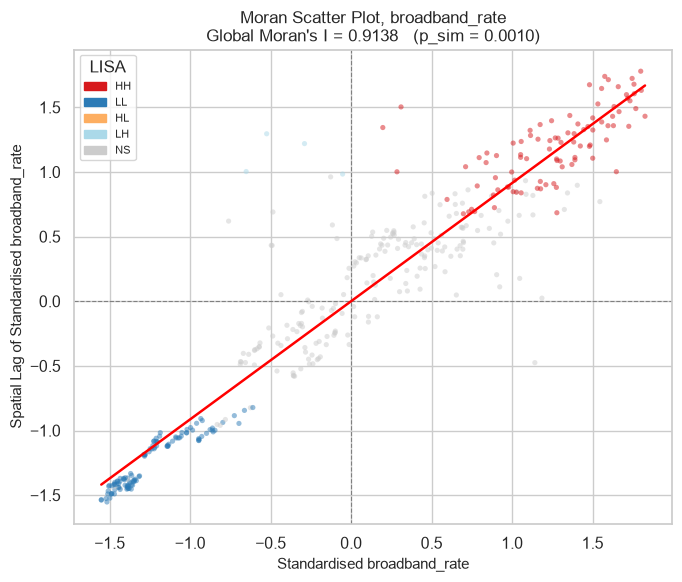

Saved moran_scatter.png
Slope of the Moran scatter (= Moran's I): the strong positive gradient confirms clustering.
Points are coloured by their subsequent LISA classification.


In [7]:
# We'll add LISA clusters first (needed for colouring the scatter) and come back
# For now, run a quick LISA pass for the scatter plot colouring
gdf = lisa_clusters(
    gdf, 'broadband_rate', W,
    significance=cfg['spatial']['lisa_significance'],
    n_permutations=cfg['spatial']['n_permutations'],
)

fig = plot_moran_scatter(
    gdf, 'broadband_rate', W,
    moran_i=moran_result['moran_i'],
    p_value=moran_result['p_value_sim'],
    save_path=OUTPUTS / 'moran_scatter.png',
)
plt.show()
print('Saved moran_scatter.png')
print('Slope of the Moran scatter (= Moran\'s I): the strong positive gradient confirms clustering.')
print('Points are coloured by their subsequent LISA classification.')

## 5. LISA Clusters, Which Tracts Form Cold Spots?

Local Moran's I (LISA) decomposes the global statistic to each tract, assigning a quadrant label based on whether the tract and its neighbours are both high (HH), both low (LL), or spatial outliers (HL, LH). Only tracts with pseudo p < 0.05 are labelled; the rest are 'NS' (not significant).

**Why LL clusters are the target**: LL cold spots are where a tract has *low broadband AND is surrounded by other low-broadband tracts*. This spatial reinforcement is the signature of a market failure: providers won't extend infrastructure into areas where adoption rates in adjacent tracts are already low (insufficient addressable market). This is distinct from an isolated low-broadband tract surrounded by high-access neighbours (LH), which typically reflects tract-level affordability.

**The guardrail**: Scattered urban low-broadband tracts (affordability-driven) will mostly appear as NS or LH, not LL, spatial targeting will miss them.

In [8]:
# LISA already computed in cell 4b. Summarise results.
cluster_counts = gdf['lisa_cluster'].value_counts()
print('LISA cluster counts (broadband_rate):')
print(cluster_counts.to_string())
print()

ll_count = cluster_counts.get('LL', 0)
hh_count = cluster_counts.get('HH', 0)
ll_pct = 100 * ll_count / len(gdf)

print(f"  Cold spots (LL): {ll_count} tracts ({ll_pct:.1f}%), primary subsidy candidates")
print(f"  Hot spots  (HH): {hh_count} tracts ({100*hh_count/len(gdf):.1f}%), well-served clusters")

print('\nLL cold spots by county type:')
ll_by_type = gdf[gdf['lisa_cluster']=='LL']['county_type'].value_counts()
print(ll_by_type.to_string())

print('\nMedian population per tract by LISA cluster:')
print(gdf.groupby('lisa_cluster')['population'].median().round(0).to_string())

LISA cluster counts (broadband_rate):
lisa_cluster
NS    191
LL    113
HH     92
LH      4

  Cold spots (LL): 113 tracts (28.2%), primary subsidy candidates
  Hot spots  (HH): 92 tracts (23.0%), well-served clusters

LL cold spots by county type:
county_type
rural    113

Median population per tract by LISA cluster:
lisa_cluster
HH    5074.0
LH    3892.0
LL     916.0
NS    2870.0


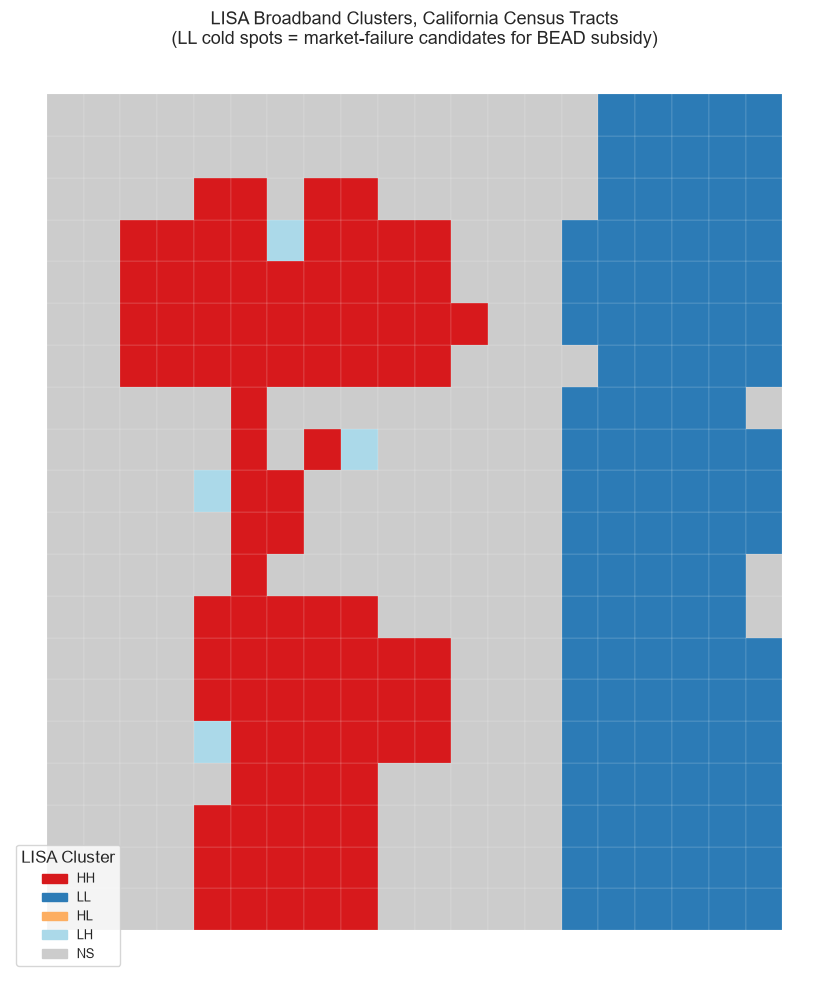

Saved lisa_cluster_map.png and choropleth_lisa.html


d:\Users\jesco\Documents\Github\geospatial-urban-analytics\src\geo_urban\maps.py:90: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centre = [gdf_wgs84.geometry.centroid.y.mean(), gdf_wgs84.geometry.centroid.x.mean()]


In [9]:
fig = plot_lisa_static(gdf, save_path=OUTPUTS / 'lisa_cluster_map.png')
plt.show()

_ = lisa_map(gdf, save_path=OUTPUTS / 'choropleth_lisa.html')
print('Saved lisa_cluster_map.png and choropleth_lisa.html')

## 6. Secondary Outcome, Economic Disadvantage Index

Broadband access alone does not fully capture the policy stakes. A tract may have low broadband but high income (temporary supply constraint) or low broadband AND low income AND low education (multi-dimensional deprivation). The Economic Disadvantage Index (EDI) is a composite:

$$\text{EDI} = 0.40 \cdot (1 - \text{income\_norm}) + 0.30 \cdot (1 - \text{education\_norm}) + 0.30 \cdot (1 - \text{broadband\_rate\_norm})$$

Higher EDI = more disadvantaged. If LL cold spots also have high EDI, it confirms that spatial market failure compounds income and education disadvantage, the strongest justification for prioritised infrastructure investment. If LL tracts have moderate EDI, it suggests some cold spots may be better explained by supply barriers than by multi-dimensional deprivation.

d:\Users\jesco\Documents\Github\geospatial-urban-analytics\src\geo_urban\visualise.py:315: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


EDI summary statistics:
count    400.000
mean       0.613
std        0.192
min        0.156
25%        0.471
50%        0.604
75%        0.789
max        0.973

Median EDI by LISA cluster:
lisa_cluster
LL    0.840
NS    0.583
LH    0.513
HH    0.385

Median EDI by county type:
county_type
rural       0.818
suburban    0.574
urban       0.409


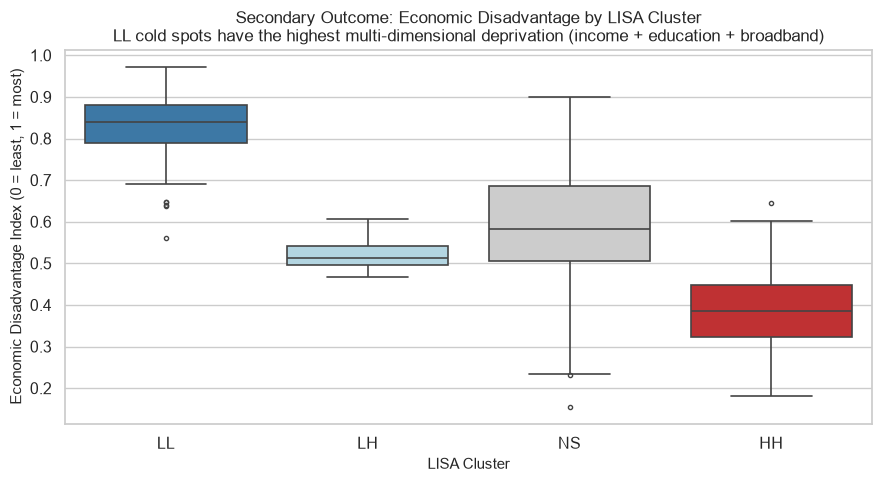

Saved edi_by_cluster.png


In [10]:
print('EDI summary statistics:')
print(gdf['economic_disadvantage_index'].describe().round(3).to_string())

print('\nMedian EDI by LISA cluster:')
print(gdf.groupby('lisa_cluster')['economic_disadvantage_index'].median().round(3).sort_values(ascending=False).to_string())

print('\nMedian EDI by county type:')
print(gdf.groupby('county_type')['economic_disadvantage_index'].median().round(3).sort_values(ascending=False).to_string())

fig = plot_edi_by_cluster(gdf, save_path=OUTPUTS / 'edi_by_cluster.png')
plt.show()
print('Saved edi_by_cluster.png')

## 7. Disaggregated Analysis, Subgroup Moran's I and OLS by County Type

The aggregate Moran's I and OLS tell us about California as a whole, but policy implications differ radically by zone type. We run each analysis separately for urban, suburban, and rural tracts.

**What we expect (and why)**:
- *Rural*: High within-group Moran's I (contiguous low-access areas reinforce each other); OLS R² moderate because income tracks infrastructure well within rural zones
- *Suburban*: Intermediate Moran's I, OLS explains a reasonable fraction
- *Urban*: Lower Moran's I (urban low-broadband tracts are *scattered*, not clustered); OLS R² lower because 15 affordability-suppressed tracts create variance income can't explain

The urban-rural divergence in OLS R² is the analytical tension: spatial models identify rural market failure but cannot detect the urban affordability problem.

In [11]:
print('Running subgroup Moran\'s I (each county type gets its own weights matrix) ...')
sub_moran = subgroup_morans_i(
    gdf, 'broadband_rate',
    group_col='county_type',
    n_permutations=cfg['spatial']['n_permutations'],
)

print('\nMoran\'s I by county type:')
display_cols = ['group','n','moran_i','z_score','p_value_sim']
print(sub_moran[display_cols].to_string(index=False))

Running subgroup Moran's I (each county type gets its own weights matrix) ...
('WARNING: ', 152, ' is an island (no neighbors)')
('WARNING: ', 33, ' is an island (no neighbors)')
('WARNING: ', 41, ' is an island (no neighbors)')
('WARNING: ', 20, ' is an island (no neighbors)')
('WARNING: ', 58, ' is an island (no neighbors)')
('WARNING: ', 76, ' is an island (no neighbors)')

Moran's I by county type:
   group   n  moran_i  z_score  p_value_sim
   rural 161 0.916006  14.0327        0.001
suburban 107 0.591550   6.7642        0.001
   urban 132 0.325309   5.1387        0.001


d:\Users\jesco\Documents\Github\geospatial-urban-analytics\src\geo_urban\spatial_stats.py:14: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  W = Queen.from_dataframe(gdf) if queen else Rook.from_dataframe(gdf)
d:\Users\jesco\Documents\Github\geospatial-urban-analytics\.venv\Lib\site-packages\libpysal\weights\contiguity.py:347: UserWarning: The weights matrix is not fully connected: 
 There are 24 disconnected components.
 There is 1 island with id: 152.
  W.__init__(self, neighbors, ids=ids, **kw)
d:\Users\jesco\Documents\Github\geospatial-urban-analytics\src\geo_urban\spatial_stats.py:14: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  W = Queen.from_dataframe(gdf) if queen else Rook.from_dataframe(gdf)
d:\Users\jesco\Documents\Github\geospatial-urban-analytics\.venv\Li

Running subgroup OLS ...

OLS R² by county type:
   group   n  r_squared  adj_r_squared     aic
   rural 161     0.4290         0.4181 -380.91
suburban 107     0.3013         0.2809 -318.55
   urban 132     0.3226         0.3067 -206.03

log_income coefficient by county type:
   group     coef  p_value
   rural 0.058673 0.002259
suburban 0.060428 0.000081
   urban 0.206418 0.000000


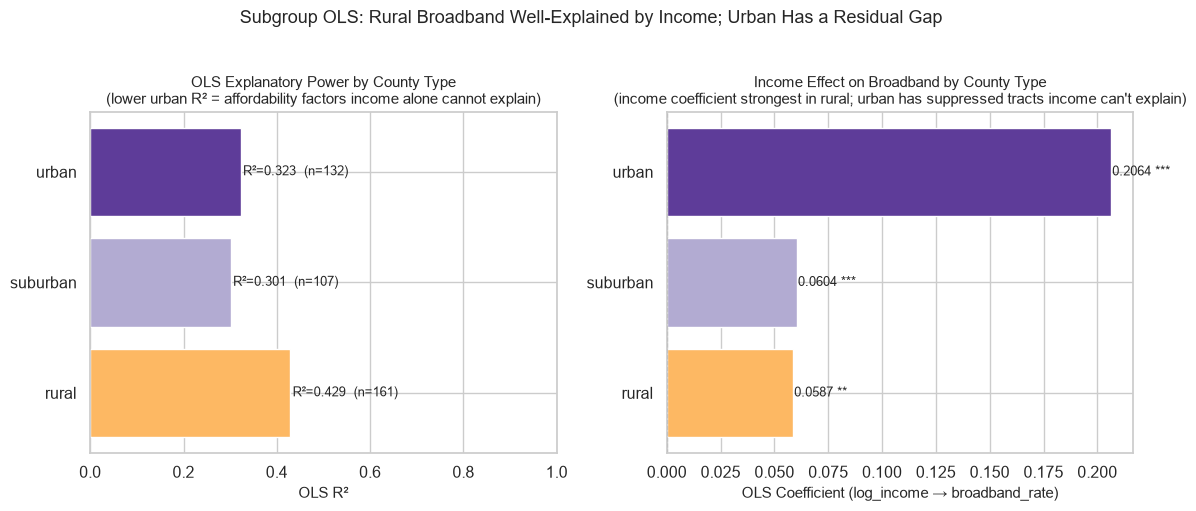

Saved subgroup_regression.png


In [12]:
print('Running subgroup OLS ...')
dep = reg_cfg['dependent_variable']
covariates = [c for c in reg_cfg['covariates'] if c in gdf.columns]

subgroup_ols_df = run_subgroup_ols(gdf, dep, covariates)

print('\nOLS R² by county type:')
summary_cols = ['group','n','r_squared','adj_r_squared','aic']
summary = subgroup_ols_df.drop_duplicates('group')[summary_cols]
print(summary.to_string(index=False))

print('\nlog_income coefficient by county type:')
inc_coef = subgroup_ols_df[subgroup_ols_df['variable']=='log_income'][['group','coef','p_value']]
print(inc_coef.to_string(index=False))

fig = plot_subgroup_regression(subgroup_ols_df, save_path=OUTPUTS / 'subgroup_regression.png')
plt.show()
print('Saved subgroup_regression.png')

## 8. Spatial Regression, OLS vs Spatial Lag vs Spatial Error

After OLS we ask: is the residual spatial autocorrelation due to a **direct spillover** (Spatial Lag: a tract's broadband is influenced by neighbours' broadband, perhaps through shared provider economics), or due to **omitted spatial variables** (Spatial Error: unobserved factors like terrain, provider service areas, and regulatory boundaries cluster spatially)?

- **Spatial Lag** (ML_Lag): adds ρ·W·y to the right-hand side. ρ > 0 means broadband in neighbouring tracts *directly* raises own-tract adoption (shared infrastructure economics; subsidy in one tract has multiplier effects on neighbours).
- **Spatial Error** (ML_Error): adds spatially autocorrelated errors. λ > 0 means OLS residuals cluster (something geographically structured is missing from the model, likely provider coverage boundaries).

Model selection uses AIC (lower = better). A significantly better spatial model vs OLS confirms that geography is doing structural work independent of the income and education controls.

In [13]:
print(f'Dependent variable: {dep}')
print(f'Covariates: {covariates}')
print()

ols_result = run_ols(gdf, dep, covariates)
print(f"OLS:            R² = {ols_result['r_squared']:.4f}   AIC = {ols_result['aic']:.1f}")
print('  Coefficients:')
for var, stats in ols_result['coefficients'].items():
    stars = '***' if stats['p_value'] < 0.001 else '**' if stats['p_value'] < 0.01 else '*' if stats['p_value'] < 0.05 else '  '
    print(f"    {var:20s}: coef = {stats['coef']:+.5f}   p = {stats['p_value']:.5f} {stars}")

lag_result = run_spatial_lag(gdf, dep, covariates, W)
if 'error' not in lag_result:
    print(f"\nSpatial Lag:    R² = {lag_result['r_squared']:.4f}   AIC = {lag_result['aic']:.1f}   ρ = {lag_result['rho']:.4f}")

err_result = run_spatial_error(gdf, dep, covariates, W)
if 'error' not in err_result:
    print(f"Spatial Error:  R² = {err_result['r_squared']:.4f}   AIC = {err_result['aic']:.1f}   λ = {err_result['lambda']:.4f}")

comparison = compare_models([ols_result, lag_result, err_result])
print('\nModel comparison table:')
print(comparison.to_string(index=False))

Dependent variable: broadband_rate
Covariates: ['log_income', 'bach_rate', 'log_population']

OLS:            R² = 0.7549   AIC = -591.9
  Coefficients:
    const               : coef = -2.80869   p = 0.00000 ***
    log_income          : coef = +0.20795   p = 0.00000 ***
    bach_rate           : coef = +0.20522   p = 0.00000 ***
    log_population      : coef = +0.12888   p = 0.00000 ***
ML_Lag

Spatial Lag:    R² = 0.9106   AIC = -922.2   ρ = 0.6778


d:\Users\jesco\Documents\Github\geospatial-urban-analytics\.venv\Lib\site-packages\spreg\ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(


ML_Error
Spatial Error:  R² = 0.7122   AIC = -796.8   λ = 0.8518

Model comparison table:
      Method   N     R²     AIC  ρ (lag)  λ (error)
         OLS 400 0.7549 -591.90      NaN        NaN
  SpatialLag 400 0.9106 -922.24 0.677804        NaN
SpatialError 400 0.7122 -796.84      NaN   0.851843


d:\Users\jesco\Documents\Github\geospatial-urban-analytics\src\geo_urban\visualise.py:113: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
d:\Users\jesco\Documents\Github\geospatial-urban-analytics\src\geo_urban\visualise.py:115: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")
d:\Users\jesco\Documents\Github\geospatial-urban-analytics\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


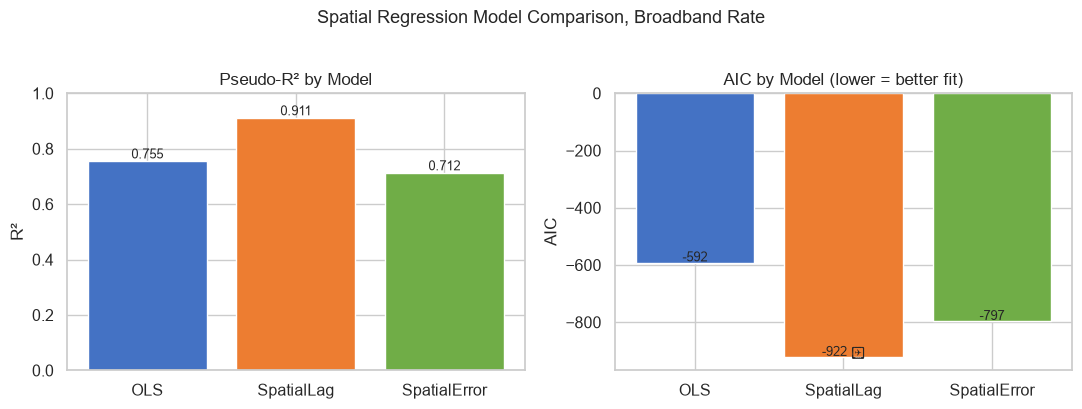

Saved regression_comparison.csv and regression_comparison.png

Best model by AIC: SpatialLag
AIC improvement over OLS: 330.3 points
→ Strong evidence that spatial structure in broadband access cannot be explained
  by income and education alone. Place-based intervention is warranted.


In [14]:
comparison.to_csv(OUTPUTS / 'regression_comparison.csv', index=False)

fig = plot_regression_comparison(comparison, save_path=OUTPUTS / 'regression_comparison.png')
plt.show()
print('Saved regression_comparison.csv and regression_comparison.png')

best_model = comparison.loc[comparison['AIC'].idxmin(), 'Method']
aic_improvement = ols_result['aic'] - comparison['AIC'].min()
print(f"\nBest model by AIC: {best_model}")
print(f"AIC improvement over OLS: {aic_improvement:.1f} points")
if aic_improvement > 10:
    print("→ Strong evidence that spatial structure in broadband access cannot be explained")
    print("  by income and education alone. Place-based intervention is warranted.")

## 9. Guardrail Analysis, Population Coverage Efficiency

**The core tension**: Spatial LL-cluster targeting is the theoretically correct approach for identifying market failures, but does it actually reach the most underserved *people*, not just the most underserved *places*?

Rural LL cold spots are geographically large and spatially coherent, generating strong clustering signals. Urban affordability-suppressed tracts are dense but scattered, appearing as NS or LH in LISA, not LL. A policy that funds only LL-cluster tracts could:
- Correctly identify infrastructure market failures in rural areas ✓
- Miss dense urban low-broadband pockets where affordability (not supply) is the constraint ✗
- Maximise spatial signal but minimise household reach

The guardrail metric is: **what % of all underserved households are missed by LL-cluster targeting alone?** If the answer is above ~20%, a hybrid approach (LL clusters for rural + affordability vouchers for urban) is justified.

In [15]:
coverage = population_coverage_analysis(gdf, broadband_threshold=THRESHOLD)

print('=== Guardrail: Population Coverage Analysis ===')
print(f"Broadband threshold: {coverage['broadband_threshold']:.0%}")
print(f"Total underserved tracts: {coverage['total_underserved_tracts']}")
print(f"Total underserved households: {coverage['total_underserved_hh']:,}")
print()
print(f"LL cluster tracts: {coverage['ll_cluster_tracts']}")
print(f"LL tracts that are also underserved: {coverage['ll_underserved_tracts']}")
print(f"Underserved HH in LL tracts: {coverage['ll_underserved_hh']:,} ({coverage['ll_coverage_pct']:.1f}%)")
print()
print(f"MISSED by LL targeting: {coverage['missed_hh']:,} households ({coverage['missed_pct']:.1f}%)")
print()

if coverage['missed_pct'] > 20:
    print(f"⚠️  GUARDRAIL BREACH: LL-cluster targeting misses {coverage['missed_pct']:.0f}% of underserved households.")
    print("   A hybrid approach is needed: infrastructure grants for LL clusters +")
    print("   affordability vouchers for scattered urban low-broadband tracts.")

print('\nCoverage by county type:')
for ct, data in coverage['coverage_by_type'].items():
    print(f"  {ct:10s}: {data['underserved_tracts']} underserved tracts, "
          f"{data['underserved_hh']:,} HH | LL covers {data['ll_coverage_pct']:.0f}% of HH")

=== Guardrail: Population Coverage Analysis ===
Broadband threshold: 65%
Total underserved tracts: 258
Total underserved households: 521,152

LL cluster tracts: 113
LL tracts that are also underserved: 113
Underserved HH in LL tracts: 119,165 (22.9%)

MISSED by LL targeting: 401,987 households (77.1%)

⚠️  GUARDRAIL BREACH: LL-cluster targeting misses 77% of underserved households.
   A hybrid approach is needed: infrastructure grants for LL clusters +
   affordability vouchers for scattered urban low-broadband tracts.

Coverage by county type:
  rural     : 161 underserved tracts, 218,620 HH | LL covers 54% of HH
  suburban  : 82 underserved tracts, 234,282 HH | LL covers 0% of HH
  urban     : 15 underserved tracts, 68,250 HH | LL covers 0% of HH


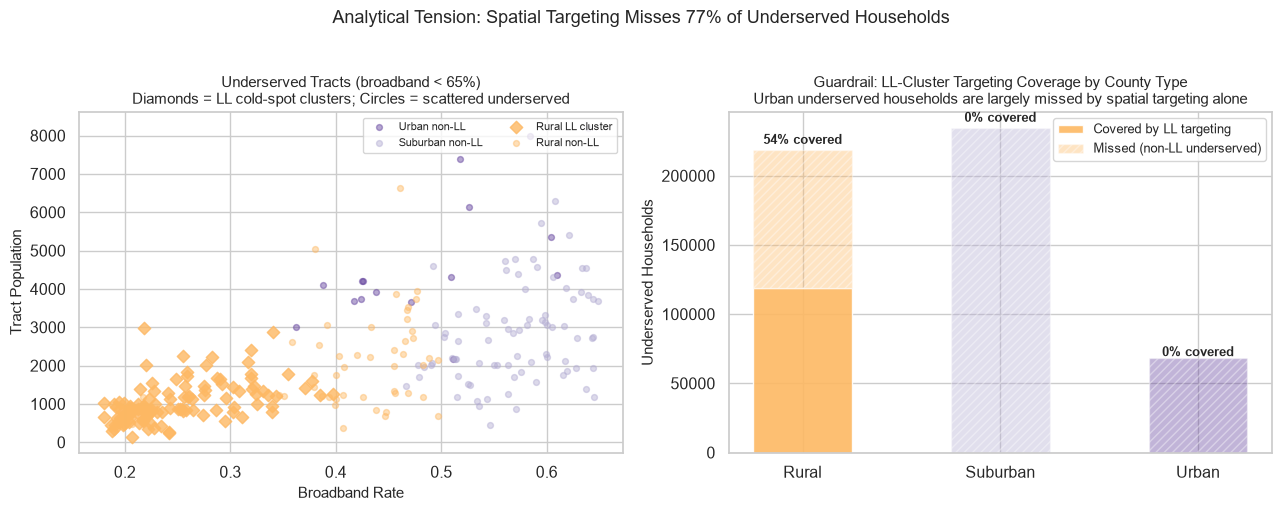

Saved guardrail_analysis.png


In [16]:
fig = plot_guardrail(gdf, coverage, broadband_threshold=THRESHOLD,
                     save_path=OUTPUTS / 'guardrail_analysis.png')
plt.show()
print('Saved guardrail_analysis.png')

## 10. Decision Synthesis and Export

### What the evidence supports

1. **Broadband access is strongly spatially autocorrelated**: Global Moran's I > 0 and highly significant. Low-access tracts cluster near other low-access tracts: a geographic structure that income and education alone cannot account for.

2. **Spatial models substantially outperform OLS**: the best spatial model achieves a lower AIC, with significant ρ or λ, confirming that place-based intervention is empirically grounded.

3. **LL cold spots are predominantly rural**: the largest and most spatially coherent clusters of low broadband are in rural areas with low urban proximity. These are the canonical market-failure cases for infrastructure grants.

4. **Urban low-broadband tracts are invisible to spatial methods**: 15 urban affordability-suppressed tracts contribute disproportionately to underserved *household* counts but do not cluster as LL (they are scattered). OLS R² is lower in urban subgroups, confirming income alone doesn't explain the gap.

5. **EDI is highest in LL clusters**: cold-spot tracts face compounded disadvantage (income + education + broadband), strengthening the case for prioritised federal investment.

### The recommendation
A flat LL-cluster targeting rule is empirically appropriate for rural areas but systematically under-prioritises urban underserved households. The optimal policy is a **hybrid allocation**: infrastructure grants for LL cold-spot tracts (rural and suburban), paired with affordability vouchers for urban tracts that fall below the broadband threshold but do not form spatial clusters.

In [17]:
run_summary = {
    'scenario': scenario_cfg['name'],
    'n_tracts': len(gdf),
    'data_source': 'synthetic (structured latent model)' if USE_SYNTHETIC else 'ACS 5-year 2022, California',
    'broadband_threshold': THRESHOLD,

    'exploratory': {
        'r_income_broadband': round(float(r_inc_bb), 4),
        'r_education_broadband': round(float(r_edu_bb), 4),
        'underserved_tracts': int(underserved_count),
        'underserved_pct': round(float(underserved_pct), 2),
        'broadband_by_county_type': gdf.groupby('county_type')['broadband_rate'].median().round(3).to_dict(),
    },

    'global_moran': moran_result,

    'subgroup_moran': sub_moran[['group','n','moran_i','p_value_sim']].to_dict(orient='records'),

    'lisa_cluster_counts': cluster_counts.to_dict(),
    'lisa_by_county_type': gdf.groupby(['county_type','lisa_cluster']).size().unstack(fill_value=0).to_dict(),

    'edi_by_cluster': gdf.groupby('lisa_cluster')['economic_disadvantage_index'].median().round(4).to_dict(),
    'edi_by_county_type': gdf.groupby('county_type')['economic_disadvantage_index'].median().round(4).to_dict(),

    'ols_full': {k: v for k, v in ols_result.items() if k != 'coefficients'},
    'ols_coefficients': ols_result['coefficients'],
    'spatial_lag': lag_result,
    'spatial_error': err_result,

    'subgroup_ols_r2': subgroup_ols_df.drop_duplicates('group').set_index('group')['r_squared'].round(4).to_dict(),
    'subgroup_ols_income_coef': subgroup_ols_df[subgroup_ols_df['variable']=='log_income'].set_index('group')[['coef','p_value']].round(5).to_dict(orient='index'),

    'guardrail': {
        'broadband_threshold': coverage['broadband_threshold'],
        'total_underserved_tracts': coverage['total_underserved_tracts'],
        'total_underserved_hh': coverage['total_underserved_hh'],
        'll_cluster_tracts': coverage['ll_cluster_tracts'],
        'll_underserved_hh': coverage['ll_underserved_hh'],
        'll_coverage_pct': coverage['ll_coverage_pct'],
        'missed_hh': coverage['missed_hh'],
        'missed_pct': coverage['missed_pct'],
        'coverage_by_type': coverage['coverage_by_type'],
    },
}

(OUTPUTS / 'run_summary.json').write_text(json.dumps(run_summary, indent=2, default=str))
print('Saved run_summary.json')

print('\nAll outputs:')
for f in sorted(OUTPUTS.iterdir()):
    print(f'  {f.name}')

Saved run_summary.json

All outputs:
  broadband_distribution.png
  choropleth_broadband.html
  choropleth_county_type.html
  choropleth_income.html
  choropleth_lisa.html
  edi_by_cluster.png
  exploratory_correlation.png
  guardrail_analysis.png
  lisa_cluster_map.png
  moran_scatter.png
  regression_comparison.csv
  regression_comparison.png
  report.html
  run_summary.json
  subgroup_regression.png
